[[ 0.000e+00 -5.660e+01 -1.050e+02 ...        nan        nan        nan]
 [ 1.000e-02 -5.800e+01 -1.039e+02 ...        nan        nan        nan]
 [ 2.000e-02 -5.870e+01 -1.033e+02 ...        nan        nan        nan]
 [ 3.000e-02 -5.950e+01 -1.028e+02 ...        nan        nan        nan]
 [ 4.000e-02 -6.080e+01 -1.017e+02 ...        nan        nan        nan]]
Control fish : 5208.2 mm
Caffeine fish: 7527.0 mm
Ratio (caffeine / control): 1.45


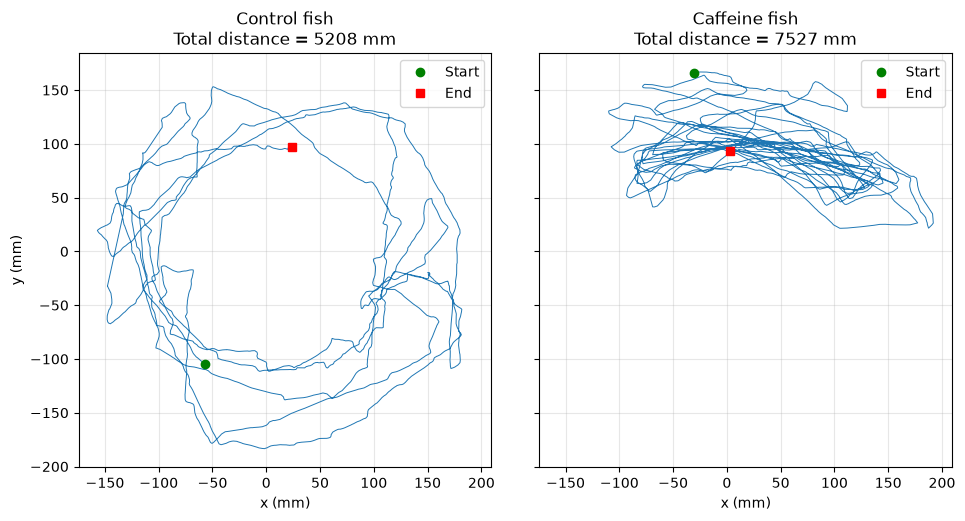

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from openpyxl import load_workbook

# 1. Load data (skip the 2 header rows)
ws = load_workbook("Data.xlsx", read_only=True).active
rows = list(ws.iter_rows(min_row=3, values_only=True))
data = np.array(rows, dtype=float)
t, cx, cy, fx, fy = data[:, 0], data[:, 1], data[:, 2], data[:, 3], data[:, 4]
print(data[:5])

# 2. Total traveling distance
def total_distance(x, y):
    return np.hypot(np.diff(x), np.diff(y)).sum()

d_ctrl = total_distance(cx, cy)
d_caf = total_distance(fx, fy)
print(f"Control fish : {d_ctrl:.1f} mm")
print(f"Caffeine fish: {d_caf:.1f} mm")
print(f"Ratio (caffeine / control): {d_caf / d_ctrl:.2f}")

# 3. Plot trajectories
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, (x, y, title, d) in zip(axes, [(cx, cy, "Control fish", d_ctrl), (fx, fy, "Caffeine fish", d_caf)]):
    ax.plot(x, y, linewidth=0.7)
    ax.plot(x[0], y[0], "go", label="Start")
    ax.plot(x[-1], y[-1], "rs", label="End")
    ax.set_title(f"{title}\nTotal distance = {d:.0f} mm")
    ax.set_xlabel("x (mm)")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("y (mm)")
plt.tight_layout()
plt.savefig("trajectories.png", dpi=200)
plt.show()


# Swimming Trajectories and Traveling Distances of Control and Caffeine-Treated Fish
*Report for the lecture "Fishes for studying neural and behavioral disorders"*

## 1. Data and Methods
The data (`Data.xlsx`) come from video analysis of fish behavior recorded by a camera mounted above a round
aquarium. The table lists time and x, y coordinates (mm) of a control fish and a caffeine fish:
5999 samples at 0.01 s intervals (about 60 s). Trajectories are drawn by plotting y against x.
The total traveling distance is the sum of straight-line distances between consecutive points:

$$D = \sum_i \sqrt{(x_{i+1}-x_i)^2 + (y_{i+1}-y_i)^2}$$

## 2. Swimming Trajectories


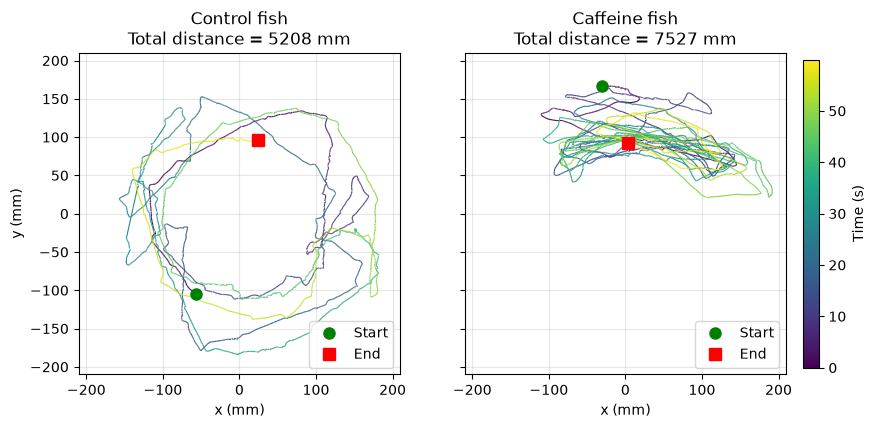

*Figure 1.* Trajectories of the control fish (left) and caffeine fish (right). Line color shows elapsed time; green circle = start, red square = end.

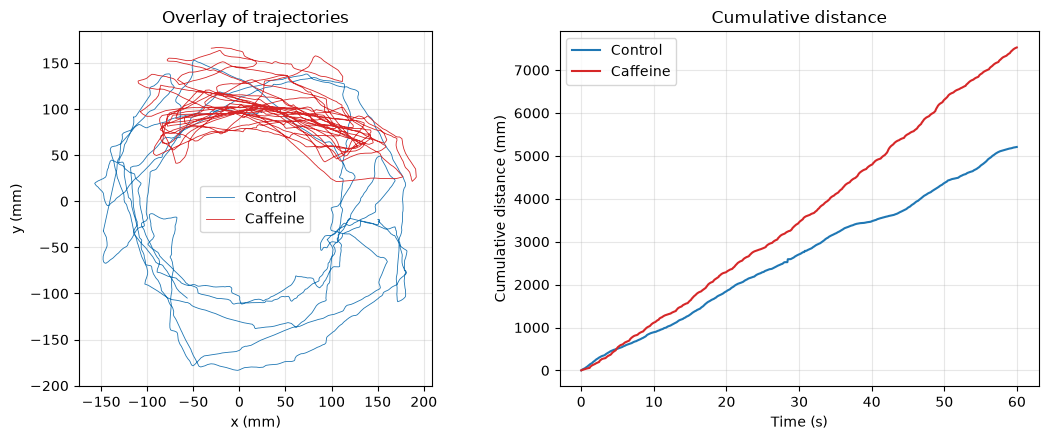

*Figure 2.* Overlay of both trajectories (left) and cumulative distance over time (right).


## 3. Total Traveling Distance

| | Control fish | Caffeine fish |
|---|---:|---:|
| Total distance (mm) | **5208.2** | **7527.0** |
| Total distance (cm) | 520.8 | 752.7 |
| Mean speed (mm/s) | 86.8 | 125.5 |
| Max step per 0.01 s (mm) | 13.7 | 6.7 |

The control fish traveled **5208 mm** in 60 s, while the caffeine fish traveled **7527 mm**,
i.e. 45% farther (ratio 1.45).

## 4. Discussion
The caffeine fish swam about 1.45 times as far as the control fish, at a higher mean speed
(125 vs 87 mm/s). The control fish swam in a roughly circular path along the tank wall and
covered the whole arena, whereas the caffeine fish stayed within a band of y = 22 to 167 mm,
in one half of the arena, repeatedly sweeping back and forth. Caffeine is a stimulant, so higher activity is
consistent with its known effect on swimming.

**Limitation:** only one fish per condition over about 60 s was analyzed, so no statistical test is possible.
Replicates with multiple fish are needed to confirm the conclusion.


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from openpyxl import load_workbook
from IPython.display import Markdown, display

plt.style.use("default")

# ---------- Load data ----------
ws = load_workbook("Data.xlsx", read_only=True).active
rows = list(ws.iter_rows(min_row=3, values_only=True))
data = np.array(rows, dtype=float)[:, :5]
t, cx, cy, fx, fy = data.T

# ---------- Distances ----------
def steps(x, y):
    return np.hypot(np.diff(x), np.diff(y))

sc, sf = steps(cx, cy), steps(fx, fy)
d_ctrl, d_caf = sc.sum(), sf.sum()
dur = t[-1] - t[0]

# ---------- Title + Methods ----------
display(Markdown(f"""
# Swimming Trajectories and Traveling Distances of Control and Caffeine-Treated Fish
*Report for the lecture "Fishes for studying neural and behavioral disorders"*

## 1. Data and Methods
The data (`Data.xlsx`) come from video analysis of fish behavior recorded by a camera mounted above a round
aquarium. The table lists time and x, y coordinates (mm) of a control fish and a caffeine fish:
{len(t)} samples at 0.01 s intervals (about {dur:.0f} s). Trajectories are drawn by plotting y against x.
The total traveling distance is the sum of straight-line distances between consecutive points:

$$D = \\sum_i \\sqrt{{(x_{{i+1}}-x_i)^2 + (y_{{i+1}}-y_i)^2}}$$

## 2. Swimming Trajectories
"""))

# ---------- Figure 1 ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, (x, y, title, d) in zip(axes, [(cx, cy, "Control fish", d_ctrl),
                                       (fx, fy, "Caffeine fish", d_caf)]):
    pts = np.array([x, y]).T.reshape(-1, 1, 2)
    lc = LineCollection(np.concatenate([pts[:-1], pts[1:]], axis=1), cmap="viridis", linewidth=0.8)
    lc.set_array(t[:-1])
    ax.add_collection(lc)
    ax.plot(x[0], y[0], "go", ms=8, label="Start")
    ax.plot(x[-1], y[-1], "rs", ms=8, label="End")
    ax.set_xlim(-210, 210); ax.set_ylim(-210, 210); ax.set_aspect("equal")
    ax.set_title(f"{title}\nTotal distance = {d:.0f} mm")
    ax.set_xlabel("x (mm)"); ax.grid(alpha=0.3); ax.legend(loc="lower right")
axes[0].set_ylabel("y (mm)")
fig.colorbar(lc, ax=axes, shrink=0.8, pad=0.02).set_label("Time (s)")
plt.savefig("trajectories.png", dpi=200, bbox_inches="tight")
plt.show()
display(Markdown("*Figure 1.* Trajectories of the control fish (left) and caffeine fish (right). "
                 "Line color shows elapsed time; green circle = start, red square = end."))

# ---------- Figure 2 ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(cx, cy, lw=0.6, c="tab:blue", label="Control")
axes[0].plot(fx, fy, lw=0.6, c="tab:red", label="Caffeine")
axes[0].set_aspect("equal"); axes[0].set_xlabel("x (mm)"); axes[0].set_ylabel("y (mm)")
axes[0].set_title("Overlay of trajectories"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(t[1:], np.cumsum(sc), c="tab:blue", label="Control")
axes[1].plot(t[1:], np.cumsum(sf), c="tab:red", label="Caffeine")
axes[1].set_xlabel("Time (s)"); axes[1].set_ylabel("Cumulative distance (mm)")
axes[1].set_title("Cumulative distance"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("overlay_cumulative.png", dpi=200)
plt.show()
display(Markdown("*Figure 2.* Overlay of both trajectories (left) and cumulative distance over time (right)."))

# ---------- Results + Discussion ----------
display(Markdown(f"""
## 3. Total Traveling Distance

| | Control fish | Caffeine fish |
|---|---:|---:|
| Total distance (mm) | **{d_ctrl:.1f}** | **{d_caf:.1f}** |
| Total distance (cm) | {d_ctrl/10:.1f} | {d_caf/10:.1f} |
| Mean speed (mm/s) | {d_ctrl/dur:.1f} | {d_caf/dur:.1f} |
| Max step per 0.01 s (mm) | {sc.max():.1f} | {sf.max():.1f} |

The control fish traveled **{d_ctrl:.0f} mm** in {dur:.0f} s, while the caffeine fish traveled **{d_caf:.0f} mm**,
i.e. {100*(d_caf/d_ctrl-1):.0f}% farther (ratio {d_caf/d_ctrl:.2f}).

## 4. Discussion
The caffeine fish swam about {d_caf/d_ctrl:.2f} times as far as the control fish, at a higher mean speed
({d_caf/dur:.0f} vs {d_ctrl/dur:.0f} mm/s). The control fish swam in a roughly circular path along the tank wall and
covered the whole arena, whereas the caffeine fish stayed within a band of y = {fy.min():.0f} to {fy.max():.0f} mm,
in one half of the arena, repeatedly sweeping back and forth. Caffeine is a stimulant, so higher activity is
consistent with its known effect on swimming.

**Limitation:** only one fish per condition over about 60 s was analyzed, so no statistical test is possible.
Replicates with multiple fish are needed to confirm the conclusion.
"""))

ASSIGNMENT REPORT ON THE MODULE "FISHES FOR STUDYING NEURAL AND BEHAVIOURAL DISORDERS"
Swimming Trajectories and Traveling Distances of Control and Caffeine-Treated Fish



1. Data and Methods

The data (Data.xlsx) of fish behavior recorded by a camera mounted above a round aquarium. The table lists time and x, y coordinates (mm) of a control fish and a caffeine fish: 5,999 samples at 0.01 s intervals (about 60 s). Trajectories are drawn by plotting y against x.

The total traveling distance is the sum of straight-line distances between consecutive points:

$$D = \sum_i \sqrt{(x_{i+1}-x_i)^2 + (y_{i+1}-y_i)^2}$$

The analysis code is in fish_analysis.ipynb.

2. Swimming Trajectories

Trajectories of control and caffeine fish

Figure 1. Trajectories of the control fish (left) and caffeine fish (right). Line color shows elapsed time; green circle = start, red square = end.

Overlay and cumulative distance

Figure 2. Overlay of both trajectories (left) and cumulative distance over time (right).

3. Total Traveling Distance
	Control fish	Caffeine fish
Total distance (mm)	5208.2	7527.0
Total distance (cm)	520.8	752.7
Mean speed (mm/s)	86.8	125.5
Max step per 0.01 s (mm)	13.7	6.7

The control fish traveled 5208 mm in 60 s, while the caffeine fish traveled 7527 mm, i.e. 45% farther (ratio 1.45).

4. Discussion

The caffeine fish swam about 1.45 times as far as the control fish, at a higher mean speed (125 vs 87 mm/s). The control fish swam in a roughly circular path along the tank wall and covered the whole arena, whereas the caffeine fish stayed within a band of y = 22 to 167 mm, in one half of the arena, repeatedly sweeping back and forth. Caffeine is a stimulant, so higher activity is consistent with its known effect on swimming.